# Βήμα 14 – Σύστημα Α: 10 εκτελέσεις σε 4 διαχωρισμούς (90-10, 80-20, 70-30, 60-40)
Ζήτηση του επιβλέποντα: κάθε εκδοχή να αξιολογείται με **10 ανεξάρτητες εκτελέσεις**, σε διαχωρισμούς εκπαίδευσης – ελέγχου
**90/10, 80/20, 70/30 και 60/40**, με τυχαία επιλογή των δειγμάτων κάθε φορά.

**Τι αλλάζει σε σχέση με τα notebooks 10–12:** εκεί χρησιμοποιήσαμε τον *επίσημο* διαχωρισμό του UNSW-NB15 (δύο αρχεία).
Εδώ ενώνουμε τα δύο αρχεία, αφαιρούμε τα διπλότυπα και ξαναχωρίζουμε τυχαία. Τα αποτελέσματα του επίσημου διαχωρισμού **μένουν** ως κύριο αποτέλεσμα
(είναι συγκρίσιμα με τη βιβλιογραφία)· αυτό το notebook προστίθεται ως έλεγχος σταθερότητας.
Αναμένουμε **υψηλότερα** νούμερα, γιατί με τυχαίο διαχωρισμό εκπαίδευση και έλεγχος έχουν την ίδια κατανομή (χάνεται η μετατόπιση κατανομής της ενότητας 4.6.1).

**Τι μένει ίδιο:** τα 8 χαρακτηριστικά, το δίκτυο (256-128-64, dropout 0.1), τα βάρη κλάσεων (p = 0.25), ο κανόνας απόφασης (κατώφλι 0.5, σοβαρότητα με κανόνα Γ).
**Καμία νέα ρύθμιση**: όλες οι επιλογές είχαν γίνει στο validation του επίσημου διαχωρισμού.

**Κάθε εκτέλεση (ίδια διαδικασία για όλες):**
1. τυχαίος διαχωρισμός εκπαίδευση / έλεγχος με το ποσοστό του διαχωρισμού (stratify στον τύπο επίθεσης)·
2. από το κομμάτι εκπαίδευσης κρατάμε 15% ως validation, μόνο για το early stopping του δικτύου·
3. προεπεξεργασία (log, κλιμάκωση) που μαθαίνεται **μόνο** από το κομμάτι εκπαίδευσης·
4. εκπαίδευση νευρωνικού και Random Forest στα ίδια δεδομένα, αξιολόγηση στο κομμάτι ελέγχου.

Η εκτέλεση k χρησιμοποιεί σπόρο k (1–10) και για τον διαχωρισμό και για το δίκτυο.

**Χρόνος: πολλές ώρες** (40 εκπαιδεύσεις δικτύου + 80 Random Forest· περίπου 5–10 λεπτά ανά εκτέλεση). Το αφήνεις να τρέχει, π.χ. το βράδυ.
Κάθε εκτέλεση **αποθηκεύεται μόλις τελειώσει** στο `models/unsw_splits_runs.csv`. Αν το διακόψεις (ή κλείσει ο υπολογιστής), ξανατρέχεις
το notebook και συνεχίζει από εκεί που σταμάτησε.

In [1]:
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss

DATA, MODELS, FIG = "../data/", "../models/", "../figures/"
RESULTS = Path(MODELS + "unsw_splits_runs.csv")
HISTORY = Path(MODELS + "unsw_splits_history.json")
SPLITS = [0.9, 0.8, 0.7, 0.6]          # ποσοστό εκπαίδευσης
RUNS = list(range(1, 11))              # 10 εκτελέσεις, σπόροι 1–10
VAL_FRACTION = 0.15                    # μέσα από το κομμάτι εκπαίδευσης, μόνο για early stopping
EPOCHS, PATIENCE = 120, 10             # όπως στο notebook 10

with open(MODELS + "unsw_meta.json", encoding="utf-8") as f:
    meta = json.load(f)
with open(MODELS + "unsw_8num_tuned_config.json", encoding="utf-8") as f:
    cfg = json.load(f)
with open(MODELS + "unsw_decision_rule.json", encoding="utf-8") as f:
    rule = json.load(f)

ATTACK_CLASSES, SEVERITY_CLASSES = meta["attack_classes"], meta["severity_classes"]
SEV_OF_ATTACK = np.array([SEVERITY_CLASSES.index(meta["severity_map"][c]) for c in ATTACK_CLASSES])
SEV_W = np.array([meta["severity_weight"][c] for c in SEVERITY_CLASSES])
FEATS = cfg["features"]
UNITS, DROPOUT, POWER = tuple(cfg["units"]), cfg["dropout"], cfg["class_weight_power"]
THRESHOLD = rule["threshold"]
CUTS = tuple(rule["severity_cuts_tuned"])
LOG_COLS = [c for c in meta["log_cols"] if c in FEATS]
PLAIN_COLS = [c for c in FEATS if c not in LOG_COLS]

print("Χαρακτηριστικά:", FEATS)
print("Δίκτυο:", UNITS, "| dropout:", DROPOUT, "| p:", POWER, "   (αναμενόμενο: (256, 128, 64) | 0.1 | 0.25)")
print("Κατώφλι:", THRESHOLD, "| όρια σοβαρότητας (κανόνας Γ):", CUTS, "   (αναμενόμενο: 0.5 | (0.55, 0.67))")

Χαρακτηριστικά: ['dur', 'dpkts', 'tcprtt', 'smean', 'trans_depth', 'ct_srv_src', 'is_ftp_login', 'is_sm_ips_ports']
Δίκτυο: (256, 128, 64) | dropout: 0.1 | p: 0.25    (αναμενόμενο: (256, 128, 64) | 0.1 | 0.25)
Κατώφλι: 0.5 | όρια σοβαρότητας (κανόνας Γ): (0.55, 0.67)    (αναμενόμενο: 0.5 | (0.55, 0.67))


## 14.1 Ένωση των δύο αρχείων και αφαίρεση διπλοτύπων
Αφαιρούμε τις γραμμές που είναι **ακριβώς ίδιες** σε όλες τις στήλες (εκτός από το `id`), ώστε η ίδια ροή να μην μπορεί να βρεθεί
ταυτόχρονα στην εκπαίδευση και στον έλεγχο. Στον επίσημο διαχωρισμό είχαμε αφαιρέσει διπλότυπα μόνο από το train.

In [2]:
parts = []
for name in ("UNSW_NB15_train-set.csv", "UNSW_NB15_test-set.csv"):
    part = pd.read_csv(DATA + name)
    part["attack_cat"] = part["attack_cat"].str.strip()
    parts.append(part)
full = pd.concat(parts, ignore_index=True)
n_all = len(full)
full = full.drop_duplicates(subset=[c for c in full.columns if c != "id"]).reset_index(drop=True)
full["severity"] = full["attack_cat"].map(meta["severity_map"])
print(f"Γραμμές: {n_all} → {len(full)} μετά την αφαίρεση {n_all - len(full)} διπλοτύπων")
print(f"Επιθέσεις: {full['label'].mean():.1%}")
print(full["attack_cat"].value_counts().to_string())

Y_ALL = {"label": full["label"].to_numpy("int64"),
         "attack_cat": full["attack_cat"].map({c: i for i, c in enumerate(ATTACK_CLASSES)}).to_numpy("int64"),
         "severity": full["severity"].map({c: i for i, c in enumerate(SEVERITY_CLASSES)}).to_numpy("int64")}
assert all((v >= 0).all() for v in Y_ALL.values()), "Άγνωστη κλάση στα δεδομένα"

Γραμμές: 257673 → 162745 μετά την αφαίρεση 94928 διπλοτύπων
Επιθέσεις: 47.3%
attack_cat
Normal            85722
Exploits          27434
Fuzzers           20960
Reconnaissance     9991
Generic            7599
DoS                5500
Analysis           2032
Backdoor           1880
Shellcode          1456
Worms               171


## 14.2 Συναρτήσεις: διαχωρισμός, δίκτυο, αξιολόγηση
Ίδιο δίκτυο, ίδια συνάρτηση σφάλματος και ίδιος κανόνας απόφασης με τα notebooks 10–12.

In [3]:
def make_split(train_frac, seed):
    """Δείκτες train / val / test για μία εκτέλεση."""
    idx = np.arange(len(full))
    tr, te = train_test_split(idx, train_size=train_frac, stratify=Y_ALL["attack_cat"], random_state=seed)
    tr, va = train_test_split(tr, test_size=VAL_FRACTION, stratify=Y_ALL["attack_cat"][tr], random_state=seed)
    return {"train": tr, "val": va, "test": te}

def make_preprocessor():
    steps = []
    if LOG_COLS:
        steps.append(("log", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                       ("scale", StandardScaler())]), LOG_COLS))
    if PLAIN_COLS:
        steps.append(("num", StandardScaler(), PLAIN_COLS))
    return ColumnTransformer(steps)

def class_weights(y_cls, n_classes, power):
    counts = np.bincount(y_cls, minlength=n_classes).astype("float64")
    w = (len(y_cls) / (n_classes * np.maximum(counts, 1))) ** power
    return (w / np.average(w, weights=counts)).astype("float32")

def weighted_sparse_ce(class_w):
    w = keras.ops.convert_to_tensor(class_w, dtype="float32")
    def loss(y_true, y_pred):
        yy = keras.ops.cast(keras.ops.reshape(y_true, (-1,)), "int32")
        return keras.losses.sparse_categorical_crossentropy(yy, y_pred) * keras.ops.take(w, yy)
    return loss

def build_model(n_in, w_attack, w_sev):
    inp = keras.Input(shape=(n_in,), name="flow_features")
    x = inp
    for i, u in enumerate(UNITS):
        x = layers.Dense(u, activation="relu", name=f"dense_{i+1}")(x)
        x = layers.BatchNormalization(name=f"bn_{i+1}")(x)
        x = layers.Dropout(DROPOUT, name=f"dropout_{i+1}")(x)
    outs = [layers.Dense(1, activation="sigmoid", name="label")(x),
            layers.Dense(len(ATTACK_CLASSES), activation="softmax", name="attack_cat")(x),
            layers.Dense(len(SEVERITY_CLASSES), activation="softmax", name="severity")(x)]
    model = keras.Model(inp, outs, name="unsw_multitask_split")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss=["binary_crossentropy", weighted_sparse_ce(w_attack), weighted_sparse_ce(w_sev)],
                  loss_weights=[1.0, 1.0, 0.5])
    return model

def targets(ix):
    return [Y_ALL["label"][ix].astype("float32").reshape(-1, 1), Y_ALL["attack_cat"][ix].astype("int32"),
            Y_ALL["severity"][ix].astype("int32")]

def detection_metrics(y, p):
    pred = (p >= THRESHOLD).astype(int)
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "FPR": ((pred == 1) & (y == 0)).sum() / max((y == 0).sum(), 1),
            "ROC-AUC": roc_auc_score(y, p), "loss": log_loss(y, np.clip(p, 1e-7, 1 - 1e-7), labels=[0, 1])}

def nn_decisions(p_label, p_attack, p_sev):
    is_attack = p_label >= THRESHOLD
    attack = np.where(is_attack, p_attack[:, 1:].argmax(1) + 1, 0)
    ps = p_sev[:, 1:]
    expected = (ps * SEV_W[1:]).sum(1) / np.clip(ps.sum(1), 1e-9, None)
    level = np.where(expected < CUTS[0], 1, np.where(expected < CUTS[1], 2, 3))
    return attack, np.where(is_attack, level, 0)

## 14.3 Μία εκτέλεση
Νευρωνικό: εκπαίδευση στο train, early stopping στο validation, αξιολόγηση στο test.
Random Forest (200 δέντρα, όπως στο notebook 10): ένα για επίθεση/όχι και ένα για τον τύπο, στο ίδιο train.

In [4]:
def run_once(train_frac, seed):
    ix = make_split(train_frac, seed)
    pre = make_preprocessor()
    X = {"train": pre.fit_transform(full.iloc[ix["train"]][FEATS]).astype("float32")}
    X["val"] = pre.transform(full.iloc[ix["val"]][FEATS]).astype("float32")
    X["test"] = pre.transform(full.iloc[ix["test"]][FEATS]).astype("float32")
    yt = {k: v[ix["test"]] for k, v in Y_ALL.items()}
    common = {"split": f"{round(train_frac * 100)}-{round((1 - train_frac) * 100)}", "run": seed,
              "n_train": len(ix["train"]), "n_val": len(ix["val"]), "n_test": len(ix["test"])}
    rows = []

    # --- νευρωνικό ---
    t0 = time.time()
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    w_att = class_weights(Y_ALL["attack_cat"][ix["train"]], len(ATTACK_CLASSES), POWER)
    w_sev = class_weights(Y_ALL["severity"][ix["train"]], len(SEVERITY_CLASSES), POWER)
    model = build_model(X["train"].shape[1], w_att, w_sev)
    hist = model.fit(X["train"], targets(ix["train"]), validation_data=(X["val"], targets(ix["val"])),
                     epochs=EPOCHS, batch_size=256, verbose=0,
                     callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
                                keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)])
    p_label, p_attack, p_sev = model.predict(X["test"], batch_size=4096, verbose=0)
    p_label = np.asarray(p_label, dtype="float64").ravel()
    attack, sev = nn_decisions(p_label, np.asarray(p_attack), np.asarray(p_sev))
    high = yt["severity"] == 3
    rows.append({"model": "Νευρωνικό", **common, **detection_metrics(yt["label"], p_label),
                 "type accuracy": accuracy_score(yt["attack_cat"], attack),
                 "type macro-F1": f1_score(yt["attack_cat"], attack, average="macro"),
                 "severity accuracy": accuracy_score(yt["severity"], sev),
                 "High→Low": float((sev[high] == 1).mean()) if high.any() else np.nan,
                 "epochs": len(hist.history["loss"]), "seconds": time.time() - t0})
    history = {k: [float(v) for v in hist.history.get(k, [])] for k in ("loss", "val_loss")}

    # --- Random Forest ---
    t0 = time.time()
    make_rf = lambda: RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=seed)
    rf_label = make_rf().fit(X["train"], Y_ALL["label"][ix["train"]])
    rf_attack = make_rf().fit(X["train"], Y_ALL["attack_cat"][ix["train"]])
    p_rf = rf_label.predict_proba(X["test"])[:, 1]
    a_rf = rf_attack.predict(X["test"])
    rows.append({"model": "Random Forest", **common, **detection_metrics(yt["label"], p_rf),
                 "type accuracy": accuracy_score(yt["attack_cat"], a_rf),
                 "type macro-F1": f1_score(yt["attack_cat"], a_rf, average="macro"),
                 "seconds": time.time() - t0})
    return rows, history

## 14.4 Οι 40 εκτελέσεις
Δείχνει μία γραμμή ανά εκτέλεση. Ό,τι έχει ήδη γίνει (υπάρχει στο `unsw_splits_runs.csv`) παραλείπεται.

In [5]:
done = pd.read_csv(RESULTS) if RESULTS.exists() else pd.DataFrame(columns=["model", "split", "run"])
histories = json.loads(HISTORY.read_text(encoding="utf-8")) if HISTORY.exists() else {}
start = time.time()
for train_frac in SPLITS:
    split_name = f"{round(train_frac * 100)}-{round((1 - train_frac) * 100)}"
    for seed in RUNS:
        if ((done["split"] == split_name) & (done["run"] == seed) & (done["model"] == "Νευρωνικό")).any():
            continue
        rows, history = run_once(train_frac, seed)
        done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True)
        done.to_csv(RESULTS, index=False)                     # αποθήκευση μετά από κάθε εκτέλεση
        histories[f"{split_name}/{seed}"] = history
        HISTORY.write_text(json.dumps(histories), encoding="utf-8")
        nn = rows[0]
        print(f"{split_name} εκτέλεση {seed:2d} | ΝΔ acc {nn['accuracy']:.4f} AUC {nn['ROC-AUC']:.4f} τύπος {nn['type accuracy']:.4f} "
              f"| RF acc {rows[1]['accuracy']:.4f} | {nn['epochs']} εποχές | {(time.time() - start) / 60:.0f} λεπτά συνολικά", flush=True)
print("Ολοκληρώθηκαν όλες οι εκτελέσεις:", len(done[done["model"] == "Νευρωνικό"]), "/", len(SPLITS) * len(RUNS))


90-10 εκτέλεση  1 | ΝΔ acc 0.8927 AUC 0.9709 τύπος 0.7798 | RF acc 0.8986 | 101 εποχές | 13 λεπτά συνολικά
90-10 εκτέλεση  2 | ΝΔ acc 0.8924 AUC 0.9704 τύπος 0.7762 | RF acc 0.8978 | 120 εποχές | 28 λεπτά συνολικά
90-10 εκτέλεση  3 | ΝΔ acc 0.8908 AUC 0.9705 τύπος 0.7790 | RF acc 0.8986 | 120 εποχές | 42 λεπτά συνολικά
90-10 εκτέλεση  4 | ΝΔ acc 0.8898 AUC 0.9705 τύπος 0.7757 | RF acc 0.8994 | 99 εποχές | 54 λεπτά συνολικά
90-10 εκτέλεση  5 | ΝΔ acc 0.8911 AUC 0.9700 τύπος 0.7746 | RF acc 0.8970 | 120 εποχές | 69 λεπτά συνολικά
90-10 εκτέλεση  6 | ΝΔ acc 0.8906 AUC 0.9704 τύπος 0.7754 | RF acc 0.8973 | 113 εποχές | 83 λεπτά συνολικά
90-10 εκτέλεση  7 | ΝΔ acc 0.8904 AUC 0.9710 τύπος 0.7759 | RF acc 0.8951 | 84 εποχές | 94 λεπτά συνολικά
90-10 εκτέλεση  8 | ΝΔ acc 0.8939 AUC 0.9708 τύπος 0.7765 | RF acc 0.8987 | 92 εποχές | 106 λεπτά συνολικά
90-10 εκτέλεση  9 | ΝΔ acc 0.8943 AUC 0.9715 τύπος 0.7762 | RF acc 0.8987 | 89 εποχές | 117 λεπτά συνολικά
90-10 εκτέλεση 10 | ΝΔ acc 0.8950 AUC 

## 14.5 Πίνακες ανά μετρική (όπως στο πρότυπο): 10 εκτελέσεις και μέσος όρος
Γραμμές = εκτελέσεις, στήλες = διαχωρισμοί. Αποθηκεύονται και σε `models/unsw_splits_table_<μετρική>.csv`.

In [6]:
res = pd.read_csv(RESULTS)
split_order = [f"{round(s * 100)}-{round((1 - s) * 100)}" for s in SPLITS]
nn = res[res["model"] == "Νευρωνικό"]
pd.set_option("display.width", 200)

def per_run_table(df, metric):
    t = df.pivot(index="run", columns="split", values=metric)[split_order]
    t.loc["Μέσος όρος"] = t.mean()
    t.loc["Τυπ. απόκλιση"] = t.iloc[:-1].std()
    return t

for metric in ["accuracy", "precision", "recall", "F1", "loss", "ROC-AUC", "FPR", "type accuracy", "severity accuracy"]:
    t = per_run_table(nn, metric)
    t.to_csv(MODELS + f"unsw_splits_table_{metric.replace(' ', '_')}.csv")
    print(f"\n=== Νευρωνικό – {metric} ===")
    print(t.round(4).to_string())


=== Νευρωνικό – accuracy ===
split           90-10   80-20   70-30   60-40
run                                          
1              0.8927  0.8899  0.8904  0.8912
2              0.8924  0.8907  0.8910  0.8911
3              0.8908  0.8895  0.8910  0.8909
4              0.8898  0.8903  0.8899  0.8884
5              0.8911  0.8911  0.8909  0.8910
6              0.8906  0.8917  0.8897  0.8905
7              0.8904  0.8907  0.8929  0.8910
8              0.8939  0.8917  0.8943  0.8935
9              0.8943  0.8941  0.8929  0.8913
10             0.8950  0.8920  0.8934  0.8921
Μέσος όρος     0.8921  0.8911  0.8916  0.8911
Τυπ. απόκλιση  0.0018  0.0013  0.0016  0.0013

=== Νευρωνικό – precision ===
split           90-10   80-20   70-30   60-40
run                                          
1              0.8960  0.8947  0.8932  0.8949
2              0.8851  0.8842  0.8840  0.8854
3              0.8860  0.8868  0.8924  0.8852
4              0.8956  0.8931  0.8899  0.8888
5              0.89

## 14.6 Σύνοψη: μέσος όρος ± τυπική απόκλιση, νευρωνικό και Random Forest
Και σύγκριση με τον επίσημο διαχωρισμό (notebooks 11–12).

In [7]:
cols = ["accuracy", "precision", "recall", "F1", "FPR", "ROC-AUC", "type accuracy", "type macro-F1", "severity accuracy", "High→Low"]
summary = []
for (model, split), g in res.groupby(["model", "split"]):
    row = {"μοντέλο": model, "διαχωρισμός": split}
    for c in cols:
        if c in g and g[c].notna().any():
            row[c] = f"{g[c].mean():.4f} ± {g[c].std():.4f}"
    summary.append(row)
summary = pd.DataFrame(summary)
summary["_o"] = summary["διαχωρισμός"].map({s: i for i, s in enumerate(split_order)})
summary = summary.sort_values(["μοντέλο", "_o"], ascending=[False, True]).drop(columns="_o")
summary.to_csv(MODELS + "unsw_splits_summary.csv", index=False)
print(summary.fillna("–").to_string(index=False))

official = {"accuracy": 0.8583, "recall": 0.9663, "FPR": 0.2740, "ROC-AUC": 0.9724, "type accuracy": 0.7165, "severity accuracy": 0.7466}
print("\nΕπίσημος διαχωρισμός (notebooks 11–12), νευρωνικό:", official)

# πόσες φορές το νευρωνικό ξεπερνά το RF στην ίδια εκτέλεση
pair = res.pivot_table(index=["split", "run"], columns="model", values=["accuracy", "ROC-AUC", "type accuracy"])
for m in ["accuracy", "ROC-AUC", "type accuracy"]:
    wins = (pair[(m, "Νευρωνικό")] > pair[(m, "Random Forest")]).groupby(level=0).sum()
    print(f"Νευρωνικό > RF στο {m}:", {s: f"{int(wins.get(s, 0))}/10" for s in split_order})

      μοντέλο διαχωρισμός        accuracy       precision          recall              F1             FPR         ROC-AUC   type accuracy   type macro-F1 severity accuracy        High→Low
    Νευρωνικό       90-10 0.8921 ± 0.0018 0.8910 ± 0.0061 0.8797 ± 0.0082 0.8853 ± 0.0023 0.0968 ± 0.0068 0.9707 ± 0.0005 0.7770 ± 0.0021 0.5088 ± 0.0088   0.7779 ± 0.0023 0.0400 ± 0.0049
    Νευρωνικό       80-20 0.8911 ± 0.0013 0.8894 ± 0.0064 0.8794 ± 0.0075 0.8843 ± 0.0015 0.0983 ± 0.0072 0.9703 ± 0.0005 0.7767 ± 0.0017 0.5081 ± 0.0148   0.7770 ± 0.0023 0.0402 ± 0.0036
    Νευρωνικό       70-30 0.8916 ± 0.0016 0.8878 ± 0.0036 0.8826 ± 0.0067 0.8852 ± 0.0021 0.1003 ± 0.0043 0.9703 ± 0.0004 0.7761 ± 0.0022 0.5072 ± 0.0072   0.7763 ± 0.0020 0.0421 ± 0.0037
    Νευρωνικό       60-40 0.8911 ± 0.0013 0.8869 ± 0.0043 0.8825 ± 0.0072 0.8847 ± 0.0019 0.1011 ± 0.0051 0.9699 ± 0.0004 0.7746 ± 0.0013 0.5030 ± 0.0107   0.7757 ± 0.0020 0.0427 ± 0.0030
Random Forest       90-10 0.8980 ± 0.0013 0.8863 ± 0.0028 0.

## 14.7 Γραφήματα
- **Εικόνα 35:** κατανομή των 10 εκτελέσεων ανά διαχωρισμό (ακρίβεια ανίχνευσης και ακρίβεια τύπου), νευρωνικό και Random Forest.
- **Εικόνα 36:** καμπύλες εκπαίδευσης του νευρωνικού (εκτέλεση 1) για κάθε διαχωρισμό.

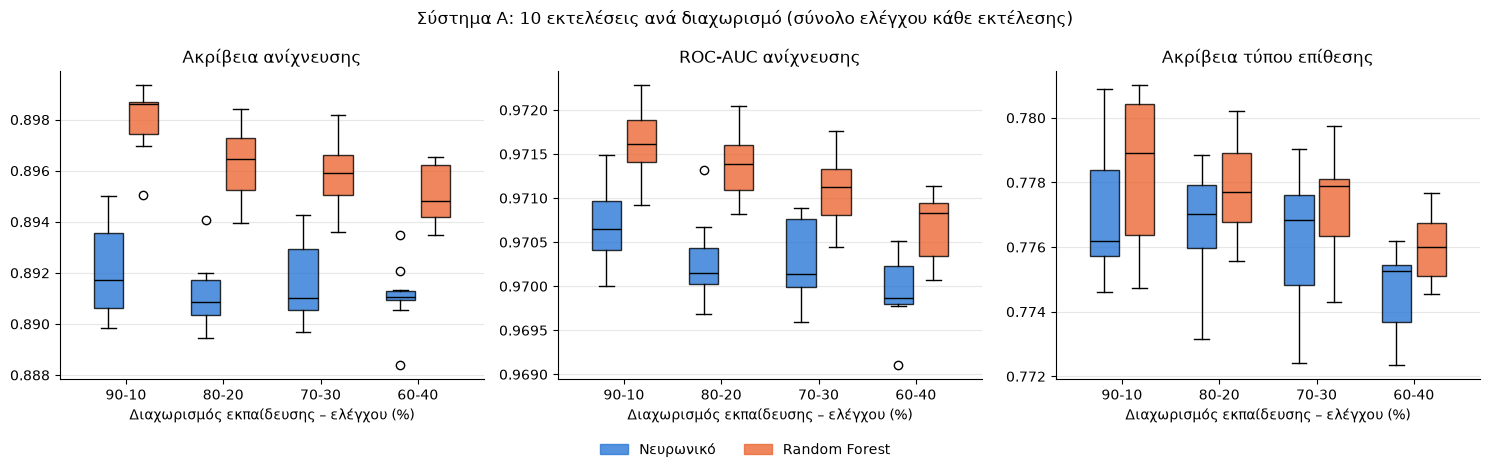

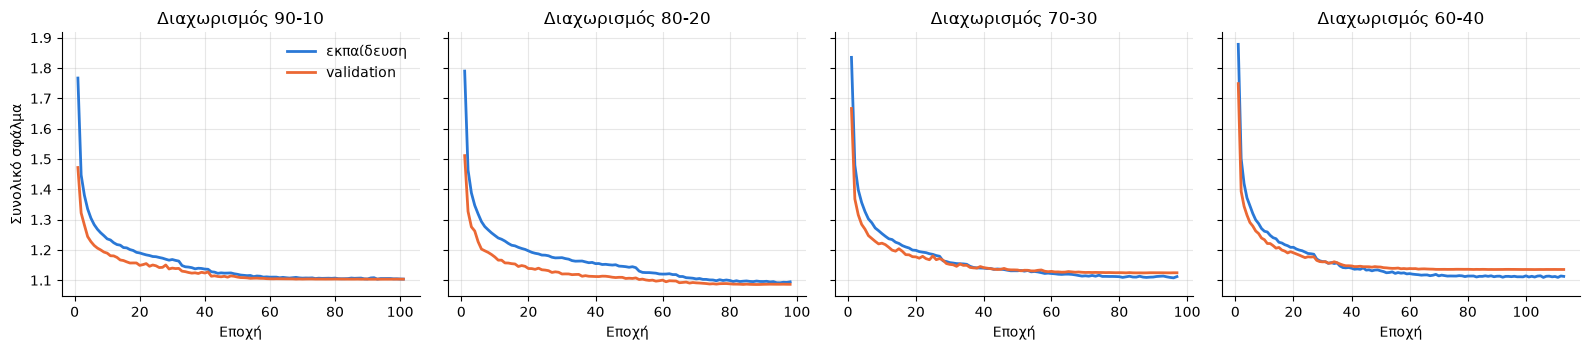

Αποθηκεύτηκαν: figures/35_splits_10runs_unsw.png, figures/36_splits_curves_unsw.png


In [8]:
COL = {"Νευρωνικό": "#2a78d6", "Random Forest": "#eb6834"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (metric, title) in zip(axes, [("accuracy", "Ακρίβεια ανίχνευσης"), ("ROC-AUC", "ROC-AUC ανίχνευσης"),
                                      ("type accuracy", "Ακρίβεια τύπου επίθεσης")]):
    pos = np.arange(len(split_order))
    for j, model in enumerate(["Νευρωνικό", "Random Forest"]):
        data = [res[(res["model"] == model) & (res["split"] == s)][metric].dropna().to_numpy() for s in split_order]
        bp = ax.boxplot(data, positions=pos + (j - 0.5) * 0.36, widths=0.3, patch_artist=True,
                        medianprops={"color": "black"}, showfliers=True)
        for box in bp["boxes"]:
            box.set(facecolor=COL[model], alpha=0.8)
    ax.set_xticks(pos, split_order)
    ax.set_xlabel("Διαχωρισμός εκπαίδευσης – ελέγχου (%)")
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=COL[m], alpha=0.8) for m in COL]
fig.legend(handles, list(COL), loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Σύστημα Α: 10 εκτελέσεις ανά διαχωρισμό (σύνολο ελέγχου κάθε εκτέλεσης)")
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIG + "35_splits_10runs_unsw.png", dpi=200, bbox_inches="tight")
plt.show()

histories = json.loads(HISTORY.read_text(encoding="utf-8"))
fig, axes = plt.subplots(1, len(split_order), figsize=(16, 3.6), sharey=True)
for ax, s in zip(axes, split_order):
    h = histories.get(f"{s}/1", {})
    ep = np.arange(1, len(h.get("loss", [])) + 1)
    ax.plot(ep, h.get("loss", []), color="#2a78d6", lw=2, label="εκπαίδευση")
    ax.plot(ep, h.get("val_loss", []), color="#eb6834", lw=2, label="validation")
    ax.set_title(f"Διαχωρισμός {s}")
    ax.set_xlabel("Εποχή")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Συνολικό σφάλμα")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG + "36_splits_curves_unsw.png", dpi=200, bbox_inches="tight")
plt.show()
print("Αποθηκεύτηκαν: figures/35_splits_10runs_unsw.png, figures/36_splits_curves_unsw.png")